<a href="https://colab.research.google.com/github/mohithkumarreddyputtur-sketch/DSA0406-FUNDAMENTAL-OF-DATA-AND-SCIENCE/blob/main/FUNDAMENTAL_OF_DATA_SCIENCE_13_TO_18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from collections import Counter
import os
import re

# Create a sample file if it doesn't exist to prevent FileNotFoundError
file_name = "sample_text.txt"
if not os.path.exists(file_name):
    with open(file_name, "w") as f:
        f.write("Hello world! This is a sample text file. Hello again, world!")

# Read text file safely using a with block
try:
    with open(file_name, "r") as file:
        text = file.read()

    # Convert to lowercase
    text = text.lower()

    # Remove punctuation
    words = re.findall(r'\b\w+\b', text)

    # Calculate frequency
    frequency = Counter(words)

    print("Word Frequency Distribution:")
    for word, count in frequency.items():
        print(f"{word} : {count}")
except FileNotFoundError:
    print(f"Error: The file '{file_name}' was not found. Please upload it to your Colab workspace.")

Word Frequency Distribution:
hello : 2
world : 2
this : 1
is : 1
a : 1
sample : 1
text : 1
file : 1
again : 1


In [ ]:
import pandas as pd

data = {
    'Age': [20, 25, 20, 30, 25, 35, 20, 30],
    'Order_Date': [
        '2026-10-05', '2026-10-10',
        '2026-10-12', '2026-10-15',
        '2026-10-18', '2026-10-20',
        '2026-10-22', '2026-10-25'
    ]
}

df = pd.DataFrame(data)

df['Order_Date'] = pd.to_datetime(df['Order_Date'])

# Filter past month's purchases
df = df[df['Order_Date'] >= '2026-10-01']

# Calculate frequency distribution
frequency = df['Age'].value_counts().sort_index()

print("Frequency Distribution of Customer Ages:")
print(frequency)

Frequency Distribution of Customer Ages:
Age
20    3
25    2
30    2
35    1
Name: count, dtype: int64


In [ ]:
import pandas as pd

data = {
    'Post_ID': [1, 2, 3, 4, 5, 6, 7],
    'Likes': [100, 200, 100, 300, 200, 100, 400]
}

df = pd.DataFrame(data)

# Calculate frequency distribution
frequency = df['Likes'].value_counts().sort_index()

print("Frequency Distribution of Likes:")
print(frequency)

Frequency Distribution of Likes:
Likes
100    3
200    2
300    1
400    1
Name: count, dtype: int64


In [ ]:
import pandas as pd
from collections import Counter
import re

data = {
    'Review': [
        'Product is very good',
        'Product is excellent',
        'Good product and good quality'
    ]
}

df = pd.DataFrame(data)

# Convert reviews into lowercase
text = ' '.join(df['Review']).lower()

# Extract words
words = re.findall(r'\b\w+\b', text)

# Calculate frequency
frequency = Counter(words)

print("Word Frequency Distribution:")
for word, count in frequency.items():
    print(word, ":", count)

Word Frequency Distribution:
product : 3
is : 2
very : 1
good : 3
excellent : 1
and : 1
quality : 1


Enter top N words (default 5): 2 5

Top 5 Most Frequent Words:
product : 2
great : 2
very : 2
quality : 2
but : 2


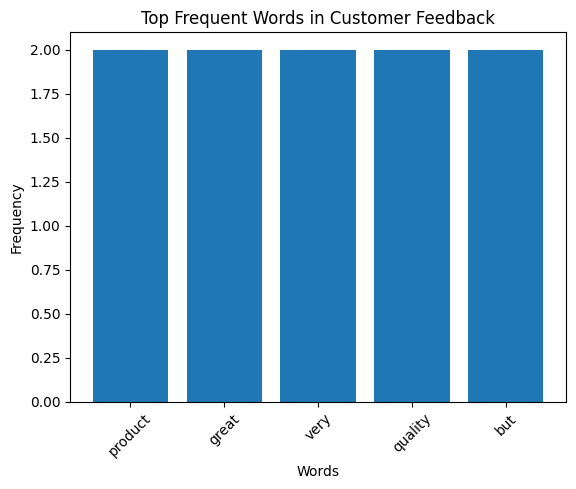

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import re
import os
from collections import Counter

# Automatically create a sample data.csv file if it doesn't exist
if not os.path.exists("data.csv"):
    sample_data = {
        'feedback': [
            'The product is great and very useful!',
            'Excellent quality, but the delivery was a bit slow.',
            'It is ok, but not worth the price.',
            'Very fast shipping. Great product quality!',
            'An absolute waste of money. It was broken.'
        ]
    }
    pd.DataFrame(sample_data).to_csv("data.csv", index=False)
    print("Note: 'data.csv' was missing, so a sample file has been automatically created for you.\n")

# Load CSV file
df = pd.read_csv("data.csv")

# Stop words
stop_words = ['the', 'and', 'is', 'a', 'an', 'to',
              'of', 'in', 'for', 'it', 'was', 'are']

# Preprocess text
words = []

for text in df['feedback'].dropna():
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)

    for word in text.split():
        if word not in stop_words:
            words.append(word)

# Calculate frequency
frequency = Counter(words)

# Get user input
try:
    # Set default of 5 if input fails/non-interactive
    n_input = input("Enter top N words (default 5): ")
    n = int(n_input) if n_input.strip() else 5
except (IOError, ValueError):
    n = 5

top_words = frequency.most_common(n)

print("\nTop", n, "Most Frequent Words:")
for word, count in top_words:
    print(word, ":", count)

# Plot bar graph
names = [x[0] for x in top_words]
counts = [x[1] for x in top_words]

plt.bar(names, counts)
plt.title("Top Frequent Words in Customer Feedback")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.show()

Mean:
Age    45.388889
Fat    27.833333
dtype: float64

Median:
Age    46.5
Fat    28.5
dtype: float64

Standard Deviation:
Age    14.283429
Fat     7.318389
dtype: float64


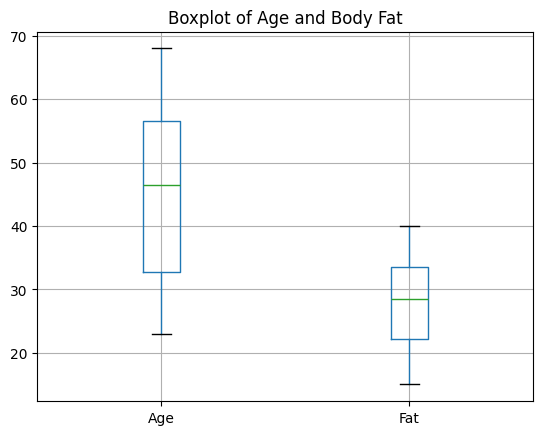

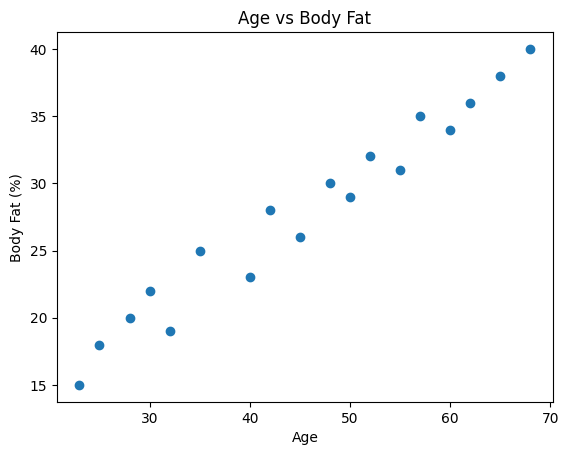

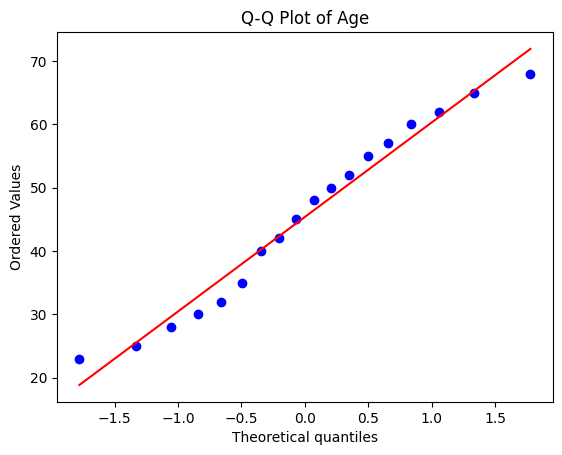

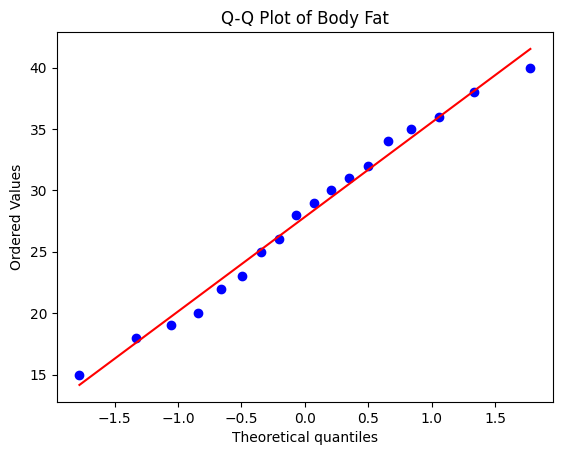

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

# Enter data for 18 adults
data = {
    'Age': [23, 25, 28, 30, 32, 35, 40, 42, 45,
            48, 50, 52, 55, 57, 60, 62, 65, 68],

    'Fat': [15, 18, 20, 22, 19, 25, 23, 28, 26,
            30, 29, 32, 31, 35, 34, 36, 38, 40]
}

df = pd.DataFrame(data)

# 1. Mean, Median and Standard Deviation
print("Mean:")
print(df.mean())

print("\nMedian:")
print(df.median())

print("\nStandard Deviation:")
print(df.std())

# 2. Boxplots
df.boxplot(column=['Age', 'Fat'])
plt.title("Boxplot of Age and Body Fat")
plt.show()

# 3. Scatter Plot
plt.scatter(df['Age'], df['Fat'])
plt.title("Age vs Body Fat")
plt.xlabel("Age")
plt.ylabel("Body Fat (%)")
plt.show()

# 4. Q-Q Plot of Age
stats.probplot(df['Age'], dist="norm", plot=plt)
plt.title("Q-Q Plot of Age")
plt.show()

# 5. Q-Q Plot of Body Fat
stats.probplot(df['Fat'], dist="norm", plot=plt)
plt.title("Q-Q Plot of Body Fat")
plt.show()